In [1]:
import pandas as pd

file_path = '../data/raw/VarDrug.csv'

data = pd.read_csv(file_path)

print(data.head())
print(data.info())

   Unnamed: 0        VariantID          Conequence    Gene       Drug  \
0           0  3_178741877_C_T      intron_variant  KCNMB2  ritodrine   
1           1  3_178743983_T_C      intron_variant  KCNMB2  ritodrine   
2           2  7_117642472_A_G    missense_variant    CFTR  ivacaftor   
3           3   7_87550285_G_A  synonymous_variant   ABCB1   fentanyl   
4           4   8_18400593_A_G    missense_variant    NAT2  isoniazid   

           SideEffect  
0  decreased-Efficacy  
1  decreased-Efficacy  
2  increased-Efficacy  
3    increased-Dosage  
4  decreased-Toxicity  
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4698 entries, 0 to 4697
Data columns (total 6 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   Unnamed: 0  4698 non-null   int64 
 1   VariantID   4698 non-null   object
 2   Conequence  4698 non-null   object
 3   Gene        4698 non-null   object
 4   Drug        4698 non-null   object
 5   SideEffect  4698 non-null 

Data Preprocessing 


1.1 Exploratory Data Analysis (EDA)


In [2]:
missing_values = data.isnull().sum()
print("\n Missing Values: \n", missing_values)


 Missing Values: 
 Unnamed: 0    0
VariantID     0
Conequence    0
Gene          0
Drug          0
SideEffect    0
dtype: int64


In [3]:
value_counts = data.apply(pd.Series.value_counts)
print("\n value counts for each column: \n", value_counts)

TypeError: '<' not supported between instances of 'str' and 'int'

In [4]:
side_effect_distribution = data['SideEffect'].value_counts()
print("\n side effect distrbution: \n", side_effect_distribution)


 side effect distrbution: 
 SideEffect
increased-Efficacy    1503
increased-PK           783
decreased-Efficacy     763
decreased-Dosage       520
decreased-PK           494
increased-Dosage       471
decreased-Toxicity      41
increased-Toxicity      38
decreased-Other         37
increased-Other         36
decreased-PD             7
increased-PD             5
Name: count, dtype: int64


اینجا دیدیم که مقادیر ستون ساید افکتز چطوری هستند.
مقادیر زیادی هستند با مقادیر غیرعددی که نیاز هم داریم به عدد تبدیل کنیم. 

In [5]:
number_of_unique_drug = data['Drug'].nunique()
print("\n Drug unique: \n", number_of_unique_drug)


 Drug unique: 
 406


In [6]:
descriptive_stats = data.describe(include='all')
descriptive_stats

,Unnamed: 0,VariantID,Conequence,Gene,Drug,SideEffect
count,4698.000000,4698,4698,4698,4698,4698
unique,NaN,1345,21,605,406,12
top,NaN,7_99672916_C_T,missense_variant,ABCB1,warfarin,increased-Efficacy
freq,NaN,242,1798,352,442,1503
mean,2348.500000,NaN,NaN,NaN,NaN,NaN
std,1356.340112,NaN,NaN,NaN,NaN,NaN
min,0.000000,NaN,NaN,NaN,NaN,NaN
25%,1174.250000,NaN,NaN,NaN,NaN,NaN
50%,2348.500000,NaN,NaN,NaN,NaN,NaN
75%,3522.750000,NaN,NaN,NaN,NaN,NaN


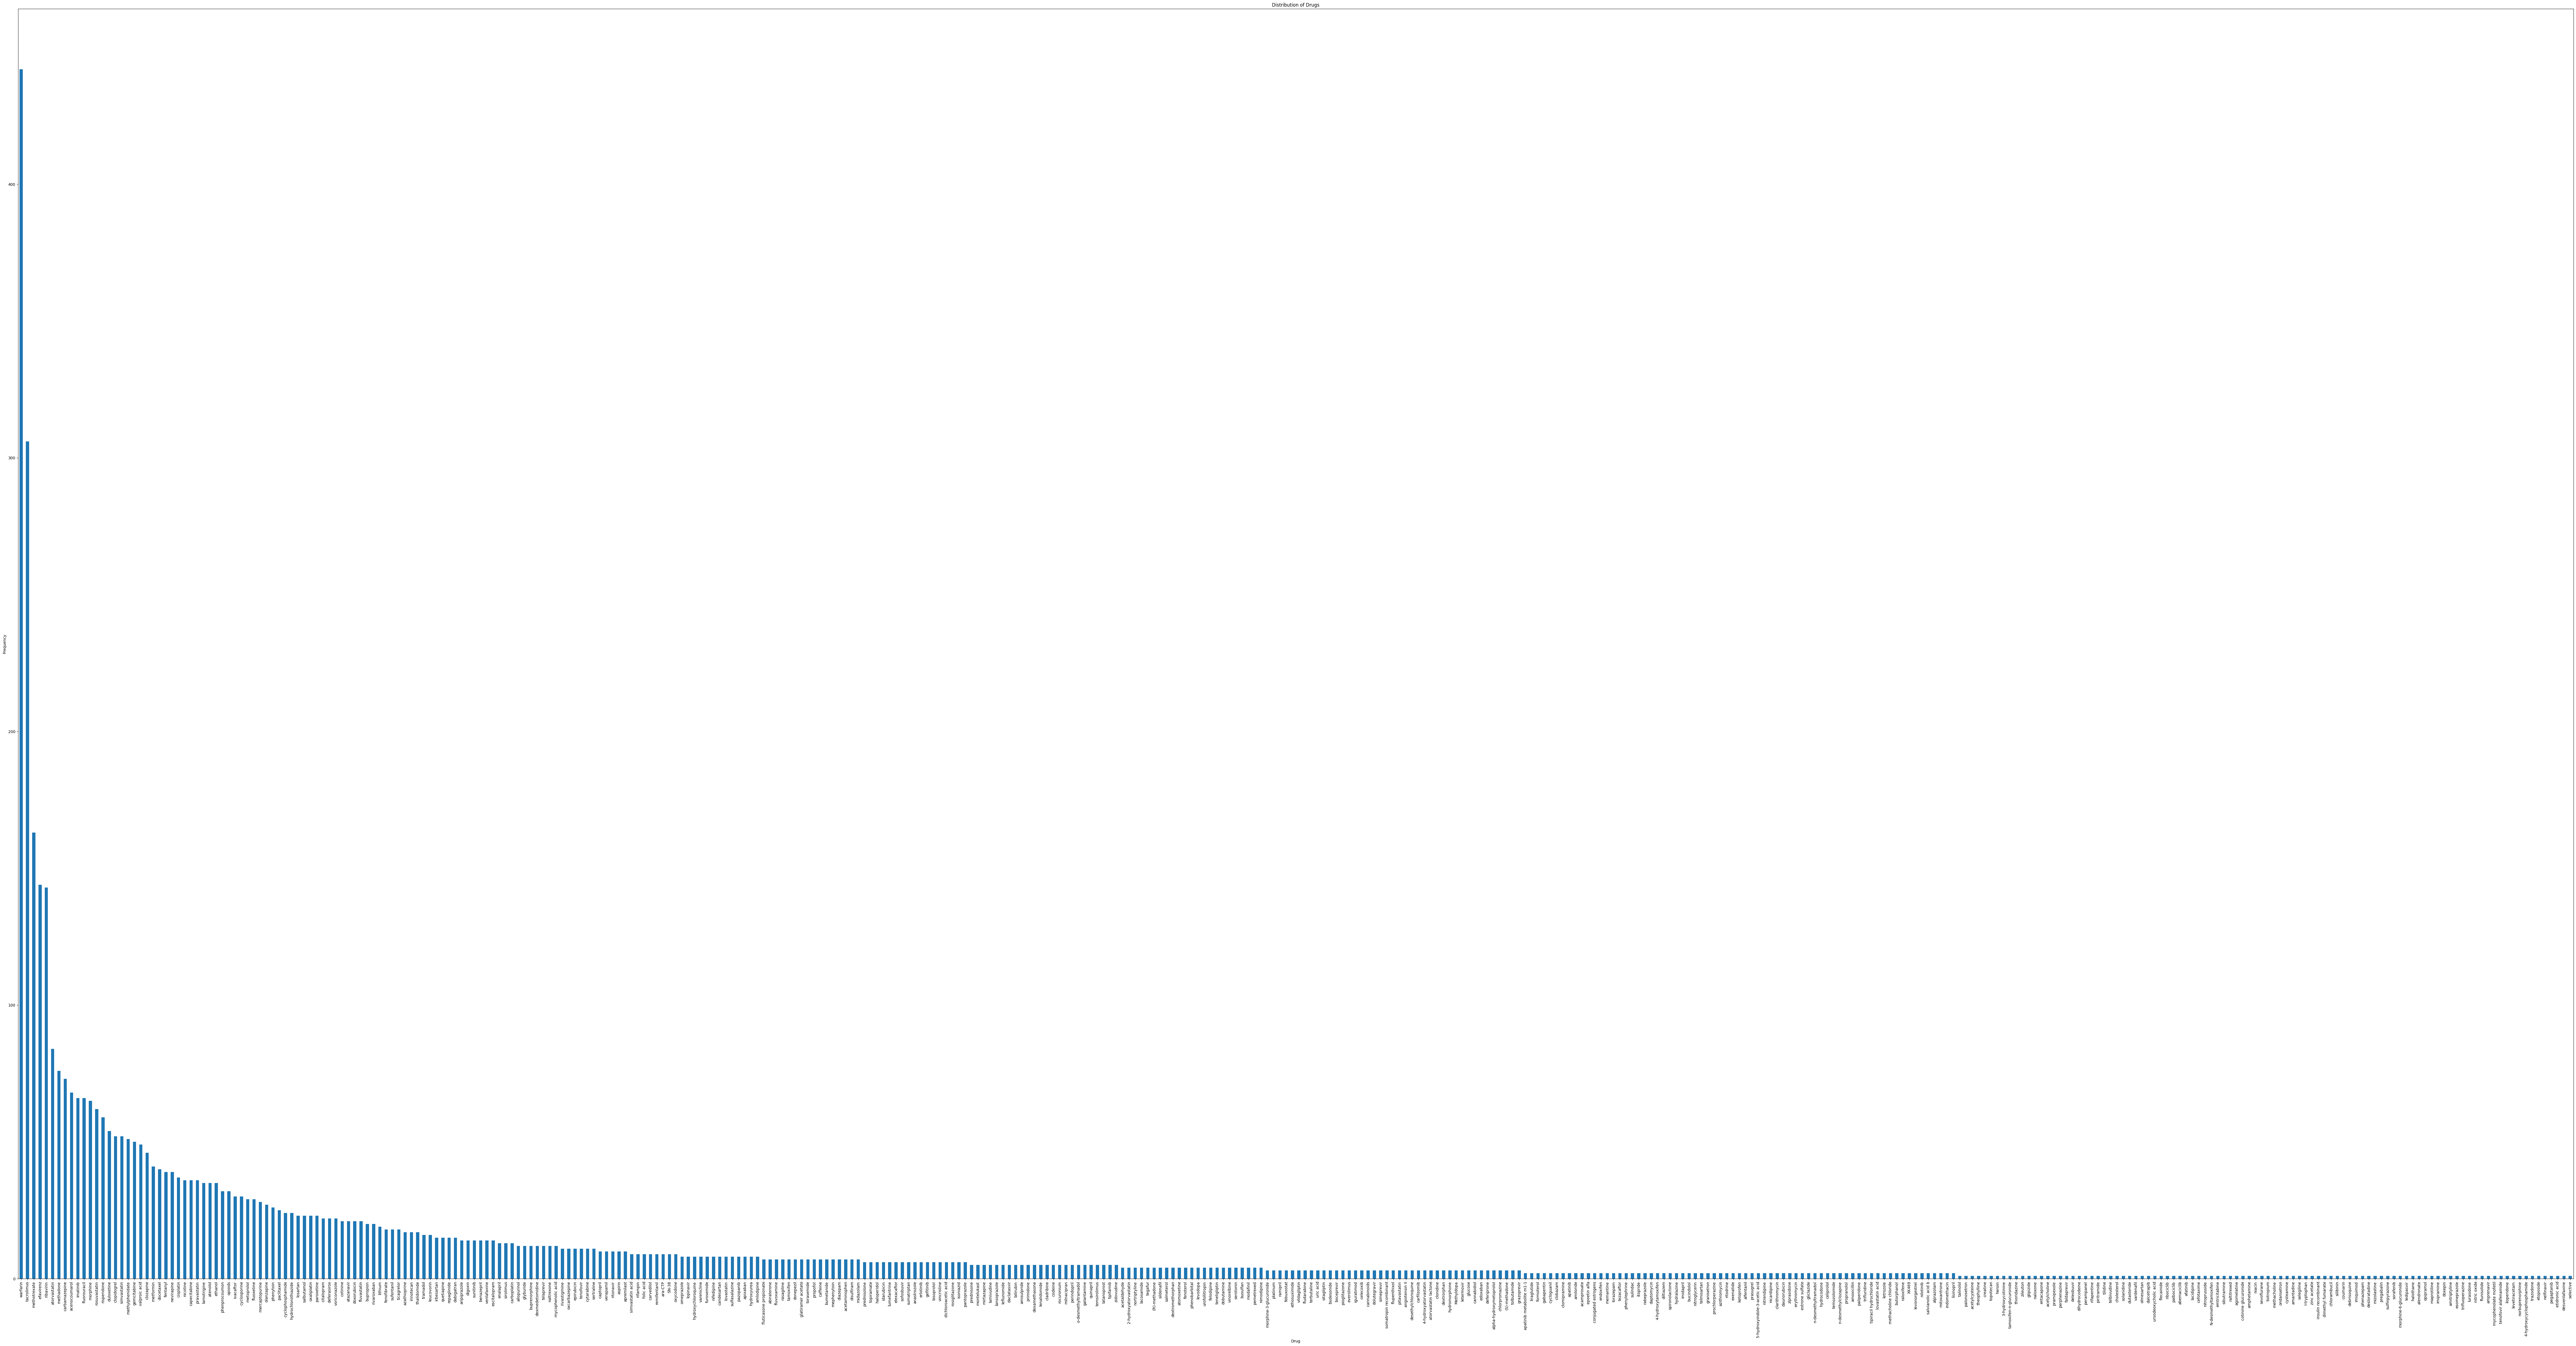

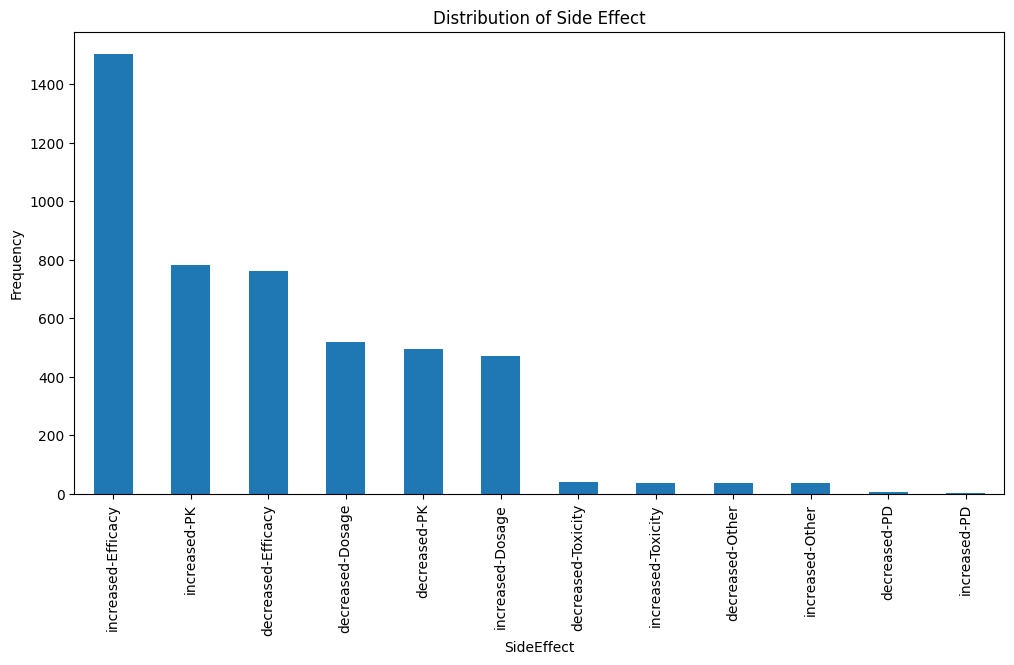

In [7]:
import matplotlib.pyplot as plt 

drug_counts = data['Drug'].value_counts()
drug_counts.plot(kind='bar', figsize=(120, 60))
plt.title('Distribution of Drugs')
plt.xlabel('Drug')
plt.ylabel('Frequency')
plt.show()

drug_counts = data['VariantID'].value_counts()
drug_counts.plot(kind='bar', figsize=(120, 60))
plt.title('Distribution of VariantID')
plt.xlabel('VariantID')
plt.ylabel('Frequency')
plt.show()

drug_counts = data['SideEffect'].value_counts()
drug_counts.plot(kind='bar', figsize=(12, 6))
plt.title('Distribution of Side Effect')
plt.xlabel('SideEffect')
plt.ylabel('Frequency')
plt.show()

1.2 Encode Categorical Features

Frequency Encoding For Side Effect column

In [8]:
side_effect_Frequency_Encoding = data['SideEffect'].value_counts()/ len(data)

data['SideEffect_encoded'] = data['SideEffect'].map(side_effect_Frequency_Encoding)
print(data[['SideEffect', 'SideEffect_encoded']].head())

           SideEffect  SideEffect_encoded
0  decreased-Efficacy            0.162410
1  decreased-Efficacy            0.162410
2  increased-Efficacy            0.319923
3    increased-Dosage            0.100255
4  decreased-Toxicity            0.008727


من روی ستون side effects اومدم و Frequency Encoding رو اجرا کردم تا به مقدار عددی برسه 

Target Encodeing For Drug Column

In [9]:
data["Drug_encoded"] = data.groupby("Drug")["SideEffect_encoded"].transform("mean")

data[["Drug", "SideEffect_encoded", "Drug_encoded"]].head(10)

,Drug,SideEffect_encoded,Drug_encoded
0,ritodrine,0.162410,0.162410
1,ritodrine,0.162410,0.162410
2,ivacaftor,0.319923,0.314673
3,fentanyl,0.100255,0.143143
4,isoniazid,0.008727,0.103768
5,risperidone,0.319923,0.245983
6,olanzapine,0.319923,0.203846
7,olanzapine,0.319923,0.203846
8,warfarin,0.110685,0.108424
9,atorvastatin,0.166667,0.218264


بعد اومدم ستون drug رو با روش target encoding با ستون هدف side effects اومدم به عددی تغییر دادم 

اینکه دو مقدار سایت افکت و دراگ انکدد مانند هم  هستند به این معناست که همیشه این دراگ همین ساید افکت رو میده و با توجه به قابلیتی که target encoding داره هر چقدر عدد دراگ انکدد از مقدار سایت افکت انکدد فاصله بگیره به این معناست که احتمال اینکه این ساید افکت از این دراگ ناشی بشه کم میشه (هرچقدر فاصله دو عدد بیشتر احتمال کمتر و هر چقدر فاصله کمتر احتمال ابتلا به ساید افکت بیشتر خواهد شد)

Target Encodeing For Gene       

In [10]:
data["Gene_encoded"] = data.groupby("Gene")["SideEffect_encoded"].transform("mean")

data[["Gene", "SideEffect_encoded", "Gene_encoded"]].head(10)


,Gene,SideEffect_encoded,Gene_encoded
0,KCNMB2,0.162410,0.162410
1,KCNMB2,0.162410,0.162410
2,CFTR,0.319923,0.315778
3,ABCB1,0.100255,0.172277
4,NAT2,0.008727,0.090336
5,HTR2A,0.319923,0.289059
6,HTR2A,0.319923,0.289059
7,HTR2A,0.319923,0.289059
8,VKORC1,0.110685,0.113363
9,SLCO1B1,0.166667,0.179301


این هم مانند قبلی اما به  جای بررسی دراگ در حال بررسی ژن هست

و البته ستون ژن رو هم به عدد تبدیل کردیم 

2. Feature Engineering 


2.1 VariantID


In [11]:
data[['Chromosome', 'Position', 'Reference_allele', 'Alternate_allele']] = data['VariantID'].str.split('_', expand=True)
data['Position'] = pd.to_numeric(data['Position'], errors='coerce')

data[['VariantID', 'Chromosome', 'Position', 'Reference_allele', 'Alternate_allele']]

,VariantID,Chromosome,Position,Reference_allele,Alternate_allele
0,3_178741877_C_T,3,178741877,C,T
1,3_178743983_T_C,3,178743983,T,C
2,7_117642472_A_G,7,117642472,A,G
3,7_87550285_G_A,7,87550285,G,A
4,8_18400593_A_G,8,18400593,A,G
...,...,...,...,...,...
4693,19_39248147_G_C,19,39248147,G,C
4694,19_39248147_G_C,19,39248147,G,C
4695,19_44908822_T_C,19,44908822,T,C
4696,19_41006936_A_G,19,41006936,A,G


استخراج ویژگی ها از VariantID
ویژگی های مختلف که در variantid بودند را استخراج کرده و هر کدام را در ستون جدایی قرار دادیم 

In [12]:
from sklearn.preprocessing import LabelEncoder

label_encoder = LabelEncoder()
data['Reference_allele_encoded'] = label_encoder.fit_transform(data['Reference_allele']) 
data['Alternate_allele_encoded'] = label_encoder.fit_transform(data['Alternate_allele']) 

data[['Alternate_allele', 'Reference_allele', 'Reference_allele_encoded', 'Alternate_allele_encoded' ]]

,Alternate_allele,Reference_allele,Reference_allele_encoded,Alternate_allele_encoded
0,T,C,10,18
1,C,T,21,9
2,G,A,1,14
3,A,G,16,1
4,G,A,1,14
...,...,...,...,...
4693,C,G,16,9
4694,C,G,16,9
4695,C,T,21,9
4696,G,A,1,14


تبدیل دو ستونی که کتگوریکال بودن به عددی با label encoding

??
آیا با target encoding به یکی از ستون های مرتبط میتونیم عدد ها رو بهتر و مرتبط تر کنیم برای ارتقای مدلمون؟

نوشن یه متلب هست در این ارتباط اون رو مطالعه کنم اگه نیاز بود

2.2 Consequence


Target Encodeing For Conequence

In [13]:
data["Conequence_encoded"] = data.groupby("Conequence")["SideEffect_encoded"].transform("mean")

data[["Conequence", "SideEffect_encoded", "Conequence_encoded"]].head(10)
    

,Conequence,SideEffect_encoded,Conequence_encoded
0,intron_variant,0.162410,0.208735
1,intron_variant,0.162410,0.208735
2,missense_variant,0.319923,0.178247
3,synonymous_variant,0.100255,0.190213
4,missense_variant,0.008727,0.178247
5,synonymous_variant,0.319923,0.190213
6,synonymous_variant,0.319923,0.190213
7,synonymous_variant,0.319923,0.190213
8,regulatory_region_variant,0.110685,0.167811
9,missense_variant,0.166667,0.178247


دلیلی که از تارگت انکدینگ هم برای این ستون استفااده شده بدیهی است بخاطر اینکه این ستون به ستون هدف یعنی ستون ساید افکت وابستگی دارد

2.3 Gene


بحث الان این هست که خانواده های ژنی و گروه بندی های بیولوژیکی ژن ها رو دربیاریم و به ره ژن اساین کنیم (دو ستون خانواده ژنی و گروه بیولوژیکی) 
بعد از اساین کردن این دو ویژگی به هر ژن بیایم اون ها رو انکدد کنیم 

In [14]:
unique_genes = data['Gene'].unique()

unique_genes

array(['KCNMB2', 'CFTR', 'ABCB1', 'NAT2', 'HTR2A', 'VKORC1', 'SLCO1B1',
       'UGT1A1', 'CYP3A7', 'CYP2D6', 'ARG2', 'SLC22A1', 'ADRB2', 'ABCG2',
       'IFNL3', 'OPRM1', 'GSTM3', 'CHRNA5', 'CYP3A5', 'ABCG8', 'CYP3A4',
       'NT5C2', 'GNB3', 'ADRA2C', 'POR', 'ABCC2', 'NFIB', 'COMT', 'IFNL4',
       'CYP1A1', 'CYP2B6', 'KCNJ6', 'CYP2C9', 'MTHFR', 'TNF', 'DRD3',
       'CNR1', 'TPH2', 'OPRL1', 'NECTIN4', 'EPHX1', 'NFKBIA', 'CSMD1',
       'DLG2', 'NR1I2', 'HTR7', 'CYP4F2', 'TPMT', 'DRD2', 'SCN1A', 'KDR',
       'P2RY12', 'VEGFA', 'HYKK', 'IL17A', 'CYP2C19', 'ADRB1', 'PEAR1',
       'ENOSF1', 'AGT', 'TYMS', 'MMP3', 'PRSS53', 'UGT2B7', 'APOE',
       'CDH2', 'CRP', 'ERCC1', 'BCL11A', 'NUDT15', 'TAOK3', 'NEDD4',
       'DDHD1', 'SLC19A1', 'AGTR1', 'ACE', 'SLC6A2', 'CYP2A6', 'APOA5',
       'KCNQ1', 'CYP4F11', 'ERCC2', 'CYP2C18', 'ADCY9', 'ABCA1',
       'SLC18A2', 'FKBP5', 'UGT1A6', 'DBH', 'CYP3A', 'NQO1', 'SLC29A1',
       'ATIC', 'VASP', 'NR3C2', 'NFKB1', 'IGF2BP2', 'COL1A1', 'DPYD',
   

In [15]:
num_unique_genes = len(unique_genes)
num_unique_genes

605

In [16]:
gene_features = {
    'KCNMB2': {'family_gene': 'Potassium channel'},
    'CFTR': {'family_gene': 'ABC transporter'},
    'ABCB1': {'family_gene': 'ABC transporter'},
    'NAT2': {'family_gene': 'N-acetyltransferase'},
    'HTR2A': {'family_gene': 'Serotonin receptor'},
    'VKORC1': {'family_gene': 'Vitamin K epoxide reductase'},
    'SLCO1B1': {'family_gene': 'Solute carrier'},
    'UGT1A1': {'family_gene': 'UDP-glucuronosyltransferase'},
    'CYP3A7': {'family_gene': 'Cytochrome P450'},
    'CYP2D6': {'family_gene': 'Cytochrome P450'},
    'ARG2': {'family_gene': 'Arginase'},
    'SLC22A1': {'family_gene': 'Solute carrier'},
    'ADRB2': {'family_gene': 'Adrenergic receptor'},
    'ABCG2': {'family_gene': 'ABC transporter'},
    'IFNL3': {'family_gene': 'Interferon'},
    'OPRM1': {'family_gene': 'Opioid receptor'},
    'GSTM3': {'family_gene': 'Glutathione S-transferase'},
    'CHRNA5': {'family_gene': 'Cholinergic receptor'},
    'CYP3A5': {'family_gene': 'Cytochrome P450'},
    'ABCG8': {'family_gene': 'ABC transporter'},
    'CYP3A4': {'family_gene': 'Cytochrome P450'},
    'NT5C2': {'family_gene': 'Nucleotidase'},
    'GNB3': {'family_gene': 'G protein subunit'},
    'ADRA2C': {'family_gene': 'Adrenergic receptor'},
    'POR': {'family_gene': 'Cytochrome P450 oxidoreductase'},
    'ABCC2': {'family_gene': 'ABC transporter'},
    'NFIB': {'family_gene': 'Nuclear factor'},
    'COMT': {'family_gene': 'Catechol-O-methyltransferase'},
    'IFNL4': {'family_gene': 'Interferon'},
    'CYP1A1': {'family_gene': 'Cytochrome P450'},
    'CYP2B6': {'family_gene': 'Cytochrome P450'},
    'KCNJ6': {'family_gene': 'Potassium channel'},
    'CYP2C9': {'family_gene': 'Cytochrome P450'},
    'MTHFR': {'family_gene': 'Methylenetetrahydrofolate reductase'},
    'TNF': {'family_gene': 'Tumor necrosis factor'},
    'DRD3': {'family_gene': 'Dopamine receptor'},
    'CNR1': {'family_gene': 'Cannabinoid receptor'},
    'TPH2': {'family_gene': 'Tryptophan hydroxylase'},
    'OPRL1': {'family_gene': 'Opioid receptor'},
    'NECTIN4': {'family_gene': 'Nectin family'},
    'EPHX1': {'family_gene': 'Epoxide hydrolase'},
    'NFKBIA': {'family_gene': 'NF-kappa-B inhibitor'},
    'CSMD1': {'family_gene': 'CSMD family'},
    'DLG2': {'family_gene': 'Discs large homolog'},
    'NR1I2': {'family_gene': 'Nuclear receptor'},
    'HTR7': {'family_gene': 'Serotonin receptor'},
    'CYP4F2': {'family_gene': 'Cytochrome P450'},
    'TPMT': {'family_gene': 'Thiopurine S-methyltransferase'},
    'DRD2': {'family_gene': 'Dopamine receptor'},
    'SCN1A': {'family_gene': 'Sodium channel'},
    'KDR': {'family_gene': 'Kinase insert domain receptor'},
    'P2RY12': {'family_gene': 'Purinergic receptor'},
    'VEGFA': {'family_gene': 'Vascular endothelial growth factor'},
    'HYKK': {'family_gene': 'Unknown'},
    'IL17A': {'family_gene': 'Interleukin'},
    'CYP2C19': {'family_gene': 'Cytochrome P450'},
    'ADRB1': {'family_gene': 'Adrenergic receptor'},
    'PEAR1': {'family_gene': 'Platelet endothelial aggregation receptor'},
    'ENOSF1': {'family_gene': 'Endothelial nitric oxide synthase'},
    'AGT': {'family_gene': 'Angiotensinogen'},
    'TYMS': {'family_gene': 'Thymidylate synthase'},
    'MMP3': {'family_gene': 'Matrix metalloproteinase'},
    'PRSS53': {'family_gene': 'Serine protease'},
    'UGT2B7': {'family_gene': 'UDP-glucuronosyltransferase'},
    'APOE': {'family_gene': 'Apolipoprotein'},
    'CDH2': {'family_gene': 'Cadherin'},
    'CRP': {'family_gene': 'C-reactive protein'},
    'ERCC1': {'family_gene': 'Excision repair cross-complementing'},
    'BCL11A': {'family_gene': 'BCL2 family'},
    'NUDT15': {'family_gene': 'Nudix hydrolase'},
    'TAOK3': {'family_gene': 'TAO kinase'},
    'NEDD4': {'family_gene': 'E3 ubiquitin-protein ligase'},
    'DDHD1': {'family_gene': 'DDHD family'},
    'SLC19A1': {'family_gene': 'Solute carrier'},
    'AGTR1': {'family_gene': 'Angiotensin receptor'},
    'ACE': {'family_gene': 'Angiotensin-converting enzyme'},
    'SLC6A2': {'family_gene': 'Solute carrier'},
    'CYP2A6': {'family_gene': 'Cytochrome P450'},
    'APOA5': {'family_gene': 'Apolipoprotein'},
    'KCNQ1': {'family_gene': 'Potassium channel'},
    'CYP4F11': {'family_gene': 'Cytochrome P450'},
    'ERCC2': {'family_gene': 'Excision repair cross-complementing'},
    'CYP2C18': {'family_gene': 'Cytochrome P450'},
    'ADCY9': {'family_gene': 'Adenylate cyclase'},
    'ABCA1': {'family_gene': 'ABC transporter'},
    'SLC18A2': {'family_gene': 'Solute carrier'},
    'FKBP5': {'family_gene': 'FK506-binding protein'},
    'UGT1A6': {'family_gene': 'UDP-glucuronosyltransferase'},
    'DBH': {'family_gene': 'Dopamine beta-hydroxylase'},
    'CYP3A': {'family_gene': 'Cytochrome P450'},
    'NQO1': {'family_gene': 'NAD(P)H dehydrogenase'},
    'SLC29A1': {'family_gene': 'Solute carrier'},
    'ATIC': {'family_gene': 'Aminoimidazole carboxamide ribonucleotide transformylase'},
    'VASP': {'family_gene': 'Vasodilator-stimulated phosphoprotein'},
    'NR3C2': {'family_gene': 'Nuclear receptor'},
    'NFKB1': {'family_gene': 'NF-kappa-B'},
    'IGF2BP2': {'family_gene': 'Insulin-like growth factor binding protein'},
    'COL1A1': {'family_gene': 'Collagen'},
    'DPYD': {'family_gene': 'Dihydropyrimidine dehydrogenase'},
    'BEST3': {'family_gene': 'Bestrophin'},
    'IL10': {'family_gene': 'Interleukin'},
    'PTPRD': {'family_gene': 'Protein tyrosine phosphatase'},
    'ATP1A2': {'family_gene': 'Sodium-potassium ATPase'},
    'TNFRSF11A': {'family_gene': 'TNF receptor'},
    'CHRNA3': {'family_gene': 'Cholinergic receptor'},
    'FSHR': {'family_gene': 'Follicle-stimulating hormone receptor'},
    'PPA2': {'family_gene': 'Phosphatase'},
    'CHRNB4': {'family_gene': 'Cholinergic receptor'},
    'ANKK1': {'family_gene': 'Ankyrin repeat domain'},
    'PSMA4': {'family_gene': 'Proteasome'},
    'MOBP': {'family_gene': 'MOB family'},
    'PDE4D': {'family_gene': 'Phosphodiesterase'},
    'TJP1': {'family_gene': 'Tight junction protein'},
    'F7': {'family_gene': 'Coagulation factor'},
    'SPOPL': {'family_gene': 'SPOP-like'},
    'GGCX': {'family_gene': 'Gamma-glutamyl carboxylase'},
    'CASP7': {'family_gene': 'Caspase'},
    'CALU': {'family_gene': 'Calumenin'},
    'SP1': {'family_gene': 'Transcription factor'},
    'CYP1A2': {'family_gene': 'Cytochrome P450'},
    'ITPA': {'family_gene': 'Inosine triphosphate pyrophosphohydrolase'},
    'MYO1H': {'family_gene': 'Myosin'},
    'FAM178B': {'family_gene': 'Family with sequence similarity'},
    'TRPV1': {'family_gene': 'Transient receptor potential channel'},
    'GSTZ1': {'family_gene': 'Glutathione S-transferase'},
    'ATM': {'family_gene': 'Ataxia telangiectasia mutated'},
    'NR1I3': {'family_gene': 'Nuclear receptor'},
    'NCAM1': {'family_gene': 'Neural cell adhesion molecule'},
    'CRHR1': {'family_gene': 'Corticotropin-releasing hormone receptor'},
    'FMO3': {'family_gene': 'Flavin-containing monooxygenase'},
    'KMT2E': {'family_gene': 'Lysine methyltransferase'},
    'ADRA2A': {'family_gene': 'Adrenergic receptor'},
    'HRH3': {'family_gene': 'Histamine receptor'},
    'SLCO1A2': {'family_gene': 'Solute carrier'},
    'IAPP': {'family_gene': 'Islet amyloid polypeptide'},
    'TTC6': {'family_gene': 'Tetratricopeptide repeat'},
    'MYLIP': {'family_gene': 'Myosin light chain interacting protein'},
    'SLC6A3': {'family_gene': 'Solute carrier'},
    'CHRNA7': {'family_gene': 'Cholinergic receptor'},
    'UGT1A4': {'family_gene': 'UDP-glucuronosyltransferase'},
    'DRD1': {'family_gene': 'Dopamine receptor'},
    'PRORP': {'family_gene': 'Proline-rich protein'},
    'PTGFR': {'family_gene': 'Prostaglandin F receptor'},
    'SLC47A1': {'family_gene': 'Solute carrier'},
    'IL18': {'family_gene': 'Interleukin'},
    'AOX1': {'family_gene': 'Aldehyde oxidase'},
    'CDA': {'family_gene': 'Cytidine deaminase'},
    'BDKRB1': {'family_gene': 'Bradykinin receptor'},
    'CACNG2': {'family_gene': 'Calcium channel'},
    'UGT1A9': {'family_gene': 'UDP-glucuronosyltransferase'},
    'ARVCF': {'family_gene': 'Armadillo repeat'},
    'SLCO2B1': {'family_gene': 'Solute carrier'},
    'CETP': {'family_gene': 'Cholesteryl ester transfer protein'},
    'ESR1': {'family_gene': 'Estrogen receptor'},
    'NEDD4L': {'family_gene': 'E3 ubiquitin ligase'},
    'UGT1A8': {'family_gene': 'UDP-glucuronosyltransferase'},
    'CACNA1C': {'family_gene': 'Calcium channel'},
    'ADGRL3': {'family_gene': 'Adhesion G protein-coupled receptor'},
    'DCK': {'family_gene': 'Deoxycytidine kinase'},
    'HLA-G': {'family_gene': 'Human leukocyte antigen'},
    'ADORA2A-AS1': {'family_gene': 'Adenosine receptor'},
    'STAT6': {'family_gene': 'Signal transducer and activator of transcription'},
    'IL1B': {'family_gene': 'Interleukin'},
    'EXO1': {'family_gene': 'Exonuclease'},
    'CAMKK2': {'family_gene': 'Calcium/calmodulin-dependent protein kinase'},
    'MAOB': {'family_gene': 'Monoamine oxidase'},
    'GATA3': {'family_gene': 'GATA transcription factor'},
    'NAMPT': {'family_gene': 'Nicotinamide phosphoribosyltransferase'},
    'MTRR': {'family_gene': 'Methionine synthase reductase'},
    'CES1': {'family_gene': 'Carboxylesterase'},
    'PACSIN2': {'family_gene': 'Protein kinase C and casein kinase substrate'},
    'KIF6': {'family_gene': 'Kinesin'},
    'SLC10A1': {'family_gene': 'Solute carrier'},
    'MTHFD1': {'family_gene': 'Methylenetetrahydrofolate dehydrogenase'},
    'GSTP1': {'family_gene': 'Glutathione S-transferase'},
    'ABAT': {'family_gene': 'Aminobutyrate aminotransferase'},
    'CBR1': {'family_gene': 'Carbonyl reductase'},
    'ADORA1': {'family_gene': 'Adenosine receptor'},
    'CALM1': {'family_gene': 'Calmodulin'},
    'CNNM2': {'family_gene': 'Cyclin and CBS domain'},
    'GGH': {'family_gene': 'Gamma-glutamyl hydrolase'},
    'FPGS': {'family_gene': 'Folylpolyglutamate synthase'},
    'SLCO1B3': {'family_gene': 'Solute carrier'},
    'ASTN2': {'family_gene': 'Astrotactin'},
    'ADRA1A': {'family_gene': 'Adrenergic receptor'},
    'CLCN6': {'family_gene': 'Chloride channel'},
    'AKR1C3': {'family_gene': 'Aldo-keto reductase'},
    'DHODH': {'family_gene': 'Dihydroorotate dehydrogenase'},
    'SLC15A1': {'family_gene': 'Solute carrier'},
    'ABCC5': {'family_gene': 'ABC transporter'},
    'HINT1': {'family_gene': 'Histidine triad nucleotide-binding protein'},
    'AOC1': {'family_gene': 'Amine oxidase'},
    'OPRD1': {'family_gene': 'Opioid receptor'},
    'PPARA': {'family_gene': 'Peroxisome proliferator-activated receptor'},
    'ADH1C': {'family_gene': 'Alcohol dehydrogenase'},
    'ALDH2': {'family_gene': 'Aldehyde dehydrogenase'},
    'ADH1B': {'family_gene': 'Alcohol dehydrogenase'},
    'ENPP2': {'family_gene': 'Ectonucleotide pyrophosphatase'},
    'DAO': {'family_gene': 'Diamine oxidase'},
    'UGT2B10': {'family_gene': 'UDP-glucuronosyltransferase'},
    'SRD5A2': {'family_gene': 'Steroid 5-alpha reductase'},
    'CYP1B1': {'family_gene': 'Cytochrome P450'},
    'MACROD2': {'family_gene': 'Macrodomain'},
    'CYP2J2': {'family_gene': 'Cytochrome P450'},
    'RAB7A': {'family_gene': 'Ras-related protein'},
    'MTNR1B': {'family_gene': 'Melatonin receptor'},
    'SNU13': {'family_gene': 'U snRNP'},
    'UGT2B15': {'family_gene': 'UDP-glucuronosyltransferase'},
    'CACNA1B': {'family_gene': 'Calcium channel'},
    'SEPTIN3': {'family_gene': 'Septin'},
    'ZNF432': {'family_gene': 'Zinc finger'},
    'IL6': {'family_gene': 'Interleukin'},
    'IGF2R': {'family_gene': 'Insulin-like growth factor receptor'},
    'GADL1': {'family_gene': 'Glutamate decarboxylase'},
    'PRKCE': {'family_gene': 'Protein kinase C'},
    'VDR': {'family_gene': 'Vitamin D receptor'},
    'ABCC4': {'family_gene': 'ABC transporter'},
    'TNIK': {'family_gene': 'TRAF2 and NCK interacting kinase'},
    'SOD2': {'family_gene': 'Superoxide dismutase'},
    'METTL21A': {'family_gene': 'Methyltransferase'},
    'SLC15A2': {'family_gene': 'Solute carrier'},
    'ABCC3': {'family_gene': 'ABC transporter'},
    'HNF1B': {'family_gene': 'Hepatocyte nuclear factor'},
    'ABCB11': {'family_gene': 'ABC transporter'},
    'RXRA': {'family_gene': 'Retinoid X receptor'},
    'SLC2A2': {'family_gene': 'Solute carrier'},
    'GRAMD1B': {'family_gene': 'GRAM domain'},
    'EPHX2': {'family_gene': 'Epoxide hydrolase'},
    'FOXP3': {'family_gene': 'Forkhead box P'},
    'ZNF385D': {'family_gene': 'Zinc finger'},
    'HSD3B1': {'family_gene': 'Hydroxysteroid dehydrogenase'},
    'CDH13': {'family_gene': 'Cadherin'},
    'BDNF': {'family_gene': 'Brain-derived neurotrophic factor'},
    'HCAR2': {'family_gene': 'Hydroxycarboxylic acid receptor'},
    'HTR1B': {'family_gene': 'Serotonin receptor'},
    'APEH': {'family_gene': 'Aminopeptidase'},
    'NR3C1': {'family_gene': 'Nuclear receptor'},
    'C6': {'family_gene': 'Complement component'},
    'GABRQ': {'family_gene': 'GABA receptor'},
    'HTR2C': {'family_gene': 'Serotonin receptor'},
    'SCN9A': {'family_gene': 'Sodium channel'},
    'TH': {'family_gene': 'Tyrosine hydroxylase'},
    'GRIN2B': {'family_gene': 'Glutamate receptor'},
    'FCGR2A': {'family_gene': 'Fc gamma receptor'},
    'NRXN1': {'family_gene': 'Neurexin'},
    'EOMES': {'family_gene': 'T-box transcription factor'},
    'TEX10': {'family_gene': 'TEX10'},
    'MIEF2': {'family_gene': 'Mitochondrial fission'},
    'TREML4': {'family_gene': 'Trem family'},
    'FCN2': {'family_gene': 'Ficolin'},
    'PVT1': {'family_gene': 'Long non-coding RNA'},
    'ANO2': {'family_gene': 'Anoctamin'},
    'MAOA': {'family_gene': 'Monoamine oxidase'},
    'KLRC1': {'family_gene': 'Killer cell lectin-like receptor'},
    'UGT1A3': {'family_gene': 'UDP-glucuronosyltransferase'},
    'BRINP3': {'family_gene': 'Bone morphogenetic protein'},
    'PADI4': {'family_gene': 'Peptidyl arginine deiminase'},
    'IL3': {'family_gene': 'Interleukin'},
    'BARD1': {'family_gene': 'BRCA1-associated'},
    'KLRK1': {'family_gene': 'Killer cell lectin-like receptor'},
    'OR10P1': {'family_gene': 'Olfactory receptor'},
    'ATP5F1E': {'family_gene': 'ATP synthase'},
    'EHF': {'family_gene': 'ETS transcription factor'},
    'SLC26A9': {'family_gene': 'Solute carrier'},
    'IL1A': {'family_gene': 'Interleukin'},
    'RRM1': {'family_gene': 'Ribonucleotide reductase'},
    'ABCC1': {'family_gene': 'ABC transporter'},
    'SNX9': {'family_gene': 'Sorting nexin'},
    'HLA-E': {'family_gene': 'Human leukocyte antigen'},
    'DTNBP1': {'family_gene': 'Dystrobrevin-binding protein'},
    'SRP19': {'family_gene': 'Signal recognition particle'},
    'REEP5': {'family_gene': 'Reep family'},
    'RRM2': {'family_gene': 'Ribonucleotide reductase'},
    'CYP24A1': {'family_gene': 'Cytochrome P450'},
    'SIN3A': {'family_gene': 'SIN3 family'},
    'CHRNB2': {'family_gene': 'Cholinergic receptor'},
    'CHRNA4': {'family_gene': 'Cholinergic receptor'},
    'ADH1A': {'family_gene': 'Alcohol dehydrogenase'},
    'TLR7': {'family_gene': 'Toll-like receptor'},
    'GRIK1': {'family_gene': 'Glutamate receptor'},
    'SELE': {'family_gene': 'Selectin'},
    'APOB': {'family_gene': 'Apolipoprotein'},
    'ERCC5': {'family_gene': 'Excision repair cross-complementing'},
    'GALNT14': {'family_gene': 'UDP-N-acetylgalactosamine transferase'},
    'CTNNB1': {'family_gene': 'Catenin'},
    'CRHR2': {'family_gene': 'Corticotropin-releasing hormone receptor'},
    'FCER1A': {'family_gene': 'High-affinity IgE receptor'},
    'SLC22A3': {'family_gene': 'Solute carrier'},
    'INSR': {'family_gene': 'Insulin receptor'},
    'XRCC1': {'family_gene': 'DNA repair protein'},
    'RUNX1': {'family_gene': 'Runt-related transcription factor'},
    'DOT1L': {'family_gene': 'Histone methyltransferase'},
    'OXT': {'family_gene': 'Oxytocin receptor'},
    'NOS1AP': {'family_gene': 'Nitric oxide synthase adapter protein'},
    'CYP19A1': {'family_gene': 'Cytochrome P450'},
    'SLC47A2': {'family_gene': 'Solute carrier'},
    'ATF2': {'family_gene': 'Activating transcription factor'},
    'ERICH3': {'family_gene': 'EH domain-containing protein'},
    'TSPAN5': {'family_gene': 'Tetraspanin'},
    'GLP1R': {'family_gene': 'Glucagon-like peptide receptor'},
    'EGFR': {'family_gene': 'Epidermal growth factor receptor'},
    'STX1B': {'family_gene': 'Syntaxin'},
    'HSD11B1': {'family_gene': 'Hydroxysteroid dehydrogenase'},
    'CYP2C8': {'family_gene': 'Cytochrome P450'},
    'GREM2': {'family_gene': 'Gremlin family'},
    'GATA4': {'family_gene': 'GATA transcription factor'},
    'NOS3': {'family_gene': 'Nitric oxide synthase'},
    'CHAT': {'family_gene': 'Choline acetyltransferase'},
    'CHRNB3': {'family_gene': 'Cholinergic receptor'},
    'PRCP': {'family_gene': 'Prolylcarboxypeptidase'},
    'COL2A1': {'family_gene': 'Collagen'},
    'PAX4': {'family_gene': 'Paired box transcription factor'},
    'GC': {'family_gene': 'Guanine nucleotide-binding protein'},
    'CRTC2': {'family_gene': 'CAMP-response element binding protein'},
    'HTR1A': {'family_gene': 'Serotonin receptor'},
    'TOLLIP': {'family_gene': 'Toll-interacting protein'},
    'SULT1A2': {'family_gene': 'Sulfotransferase'},
    'CAPN10': {'family_gene': 'Calpain'},
    'CARD16': {'family_gene': 'Caspase recruitment domain'},
    'TUT7': {'family_gene': 'TUTase family'},
    'ARID5B': {'family_gene': 'AT-rich interactive domain'},
    'CASP1': {'family_gene': 'Caspase'},
    'IL21R': {'family_gene': 'Interleukin receptor'},
    'CYP7A1': {'family_gene': 'Cytochrome P450'},
    'BCHE': {'family_gene': 'Butyrylcholinesterase'},
    'SNAP25': {'family_gene': 'Synaptosomal-associated protein'},
    'LRP1': {'family_gene': 'Low-density lipoprotein receptor-related protein'},
    'SULT1C4': {'family_gene': 'Sulfotransferase'},
    'RALBP1': {'family_gene': 'Ral-binding protein'},
    'SCN2A': {'family_gene': 'Sodium channel'},
    'GRID2': {'family_gene': 'Glutamate receptor'},
    'CMPK1': {'family_gene': 'Cytosolic nucleotide kinase'},
    'GRM7': {'family_gene': 'Metabotropic glutamate receptor'},
    'ASS1': {'family_gene': 'Argininosuccinate synthetase'},
    'RAC2': {'family_gene': 'Rac GTPase'},
    'NCF4': {'family_gene': 'Neutrophil cytosolic factor'},
    'MDM4': {'family_gene': 'Mdm4 p53 regulator'},
    'CHST3': {'family_gene': 'Carbohydrate sulfotransferase'},
    'CDK4': {'family_gene': 'Cyclin-dependent kinase'},
    'PPARD': {'family_gene': 'Peroxisome proliferator-activated receptor'},
    'STX4': {'family_gene': 'Syntaxin'},
    'DUSP1': {'family_gene': 'Dual-specificity phosphatase'},
    'IFNG': {'family_gene': 'Interferon'},
    'SLC7A5': {'family_gene': 'Solute carrier'},
    'IFNAR1': {'family_gene': 'Interferon receptor'},
    'CCR5': {'family_gene': 'C-C chemokine receptor'},
    'CPA6': {'family_gene': 'Carboxypeptidase'},
    'PRPF31': {'family_gene': 'Pre-mRNA processing factor'},
    'TGFB1': {'family_gene': 'Transforming growth factor-beta'},
    'DCTD': {'family_gene': 'Dihydropyrimidine dehydrogenase'},
    'APOA1': {'family_gene': 'Apolipoprotein'},
    'SLC28A2': {'family_gene': 'Solute carrier'},
    'MLLT3': {'family_gene': 'Myeloid/lymphoid or mixed-lineage leukemia'},
    'TDP1': {'family_gene': 'Tyrosyl-DNA phosphodiesterase'},
    'YBX1': {'family_gene': 'Y-box binding protein'},
    'GALNT18': {'family_gene': 'UDP-N-acetylgalactosamine transferase'},
    'FCAR': {'family_gene': 'Fc alpha receptor'},
    'GPR83': {'family_gene': 'G-protein coupled receptor'},
    'GRM3': {'family_gene': 'Metabotropic glutamate receptor'},
    'ADORA2A': {'family_gene': 'Adenosine receptor'},
    'AMPD1': {'family_gene': 'Adenosine monophosphate deaminase'},
    'TXNDC11': {'family_gene': 'Thioredoxin domain-containing'},
    'ADA': {'family_gene': 'Adenosine deaminase'},
    'XIRP2': {'family_gene': 'X-inactive specific transcript'},
    'AKT1': {'family_gene': 'AKT serine/threonine kinase'},
    'TLR2': {'family_gene': 'Toll-like receptor'},
    'CYP3A43': {'family_gene': 'Cytochrome P450'},
    'LIPC': {'family_gene': 'Hepatic lipase'},
    'SCARB1': {'family_gene': 'Scavenger receptor'},
    'PON1': {'family_gene': 'Paraoxonase'},
    'CXCL12': {'family_gene': 'C-X-C motif chemokine'},
    'SORCS2': {'family_gene': 'Sortilin'},
    'ACY3': {'family_gene': 'Acyclic nucleotide phosphodiesterase'},
    'SLC30A8': {'family_gene': 'Solute carrier'},
    'SLC22A2': {'family_gene': 'Solute carrier'},
    'ORM2': {'family_gene': 'Orosomucoid'},
    'KCNJ11': {'family_gene': 'Potassium channel'},
    'PROC': {'family_gene': 'Protein C'},
    'HTR3A': {'family_gene': 'Serotonin receptor'},
    'USP24': {'family_gene': 'Ubiquitin-specific protease'},
    'LPA': {'family_gene': 'Lipoprotein(a)'},
    'FMO5': {'family_gene': 'Flavin-containing monooxygenase'},
    'GRIA3': {'family_gene': 'Glutamate receptor'},
    'GRIK4': {'family_gene': 'Glutamate receptor'},
    'SLC22A5': {'family_gene': 'Solute carrier'},
    'SLC22A4': {'family_gene': 'Solute carrier'},
    'LGR5': {'family_gene': 'Leucine-rich repeat-containing G-protein coupled receptor'},
    'EIF3A': {'family_gene': 'Eukaryotic translation initiation factor'},
    'TCF7L2': {'family_gene': 'Transcription factor'},
    'SCAP': {'family_gene': 'SREBP cleavage-activating protein'},
    'UGT1A': {'family_gene': 'UDP-glucuronosyltransferase'},
    'SLC28A1': {'family_gene': 'Solute carrier'},
    'CTPS1': {'family_gene': 'Cytidine triphosphate synthetase'},
    'SLC28A3': {'family_gene': 'Solute carrier'},
    'F3': {'family_gene': 'Coagulation factor'},
    'NR1D1': {'family_gene': 'Nuclear receptor'},
    'GABRA1': {'family_gene': 'GABA receptor'},
    'PAPPA2': {'family_gene': 'Pappalysin'},
    'SLC24A4': {'family_gene': 'Solute carrier'},
    'NCOA3': {'family_gene': 'Nuclear receptor coactivator'},
    'NPPA-AS1': {'family_gene': 'Non-coding RNA'},
    'ADD1': {'family_gene': 'Adducin'},
    'PPM1A': {'family_gene': 'Protein phosphatase'},
    'SLC12A3': {'family_gene': 'Solute carrier'},
    'LDLR': {'family_gene': 'Low-density lipoprotein receptor'},
    'LPL': {'family_gene': 'Lipoprotein lipase'},
    'ADM': {'family_gene': 'Adrenomedullin'},
    'SERPINE1': {'family_gene': 'Serine protease inhibitor'},
    'MVK': {'family_gene': 'Mevalonate kinase'},
    'TP53': {'family_gene': 'Tumor suppressor'},
    'LPIN1': {'family_gene': 'Lipin'},
    'TPH1': {'family_gene': 'Tryptophan hydroxylase'},
    'NAT1': {'family_gene': 'N-acetyltransferase'},
    'GSK3B': {'family_gene': 'Glycogen synthase kinase'},
    'SRPRB': {'family_gene': 'Signal recognition particle receptor'},
    'GSTA1': {'family_gene': 'Glutathione S-transferase'},
    'PGM1': {'family_gene': 'Phosphoglucomutase'},
    'GNAS': {'family_gene': 'G protein alpha subunit'},
    'TSPYL1': {'family_gene': 'TSPY-like protein'},
    'N6AMT1': {'family_gene': 'N6-adenine methyltransferase'},
    'KCNK3': {'family_gene': 'Potassium channel'},
    'CSK': {'family_gene': 'C-src kinase'},
    'PDE3A': {'family_gene': 'Phosphodiesterase'},
    'CYP11B2': {'family_gene': 'Cytochrome P450'},
    'REV1': {'family_gene': 'DNA polymerase'},
    'PLCE1': {'family_gene': 'Phospholipase C'},
    'ADO': {'family_gene': 'Adenosine deaminase'},
    'NUCB2': {'family_gene': 'Nucleobindin'},
    'SULT1C3': {'family_gene': 'Sulfotransferase'},
    'STN1': {'family_gene': 'Stn1-like protein'},
    'C5orf56': {'family_gene': 'Chromosome 5 open reading frame'},
    'SH2B3': {'family_gene': 'SH2 domain-containing adaptor protein'},
    'SULT1A1': {'family_gene': 'Sulfotransferase'},
    'C18orf56': {'family_gene': 'Chromosome 18 open reading frame'},
    'MTR': {'family_gene': 'Methionine synthase'},
    'INVS': {'family_gene': 'Invadolysin'},
    'CACNA1H': {'family_gene': 'Calcium channel'},
    'ATP10A': {'family_gene': 'ATPase'},
    'CACNA1I': {'family_gene': 'Calcium channel'},
    'TTC37': {'family_gene': 'Tetratricopeptide repeat'},
    'XDH': {'family_gene': 'Xanthine dehydrogenase'},
    'HMGCR': {'family_gene': '3-hydroxy-3-methylglutaryl-CoA reductase'},
    'RGS4': {'family_gene': 'Regulator of G-protein signaling'},
    'LAMB3': {'family_gene': 'Laminin'},
    'BMP5': {'family_gene': 'Bone morphogenetic protein'},
    'GP1BA': {'family_gene': 'Glycoprotein Ib alpha'},
    'CA10': {'family_gene': 'Carbonic anhydrase'},
    'SLC14A2': {'family_gene': 'Solute carrier'},
    'VKORC1L1': {'family_gene': 'Vitamin K epoxide reductase'},
    'ACHE': {'family_gene': 'Acetylcholinesterase'},
    'UGT1A10': {'family_gene': 'UDP-glucuronosyltransferase'},
    'ULK3': {'family_gene': 'Unc-51-like kinase'},
    'P2RX7': {'family_gene': 'Purinergic receptor'},
    'DRD4': {'family_gene': 'Dopamine receptor'},
    'MICB': {'family_gene': 'MHC class I polypeptide-related sequence'},
    'CNTF': {'family_gene': 'Ciliary neurotrophic factor'},
    'SUMO4': {'family_gene': 'Small ubiquitin-like modifier'},
    'CACNA1E': {'family_gene': 'Calcium channel'},
    'XRCC3': {'family_gene': 'DNA repair protein'},
    'DNMT3A': {'family_gene': 'DNA methyltransferase'},
    'OPRK1': {'family_gene': 'Opioid receptor'},
    'PEBP4': {'family_gene': 'Phosphatidylethanolamine-binding protein'},
    'SLC6A4': {'family_gene': 'Solute carrier'},
    'ORMDL3': {'family_gene': 'Orosomucoid'},
    'TBXT': {'family_gene': 'T-box transcription factor'},
    'CYP4A11': {'family_gene': 'Cytochrome P450'},
    'LRRC15': {'family_gene': 'Leucine-rich repeat'},
    'ZMAT4': {'family_gene': 'Zinc finger matrin-type'},
    'GAL': {'family_gene': 'Galactosidase'},
    'SLC25A31': {'family_gene': 'Solute carrier'},
    'KLRD1': {'family_gene': 'Killer cell lectin-like receptor'},
    'RICTOR': {'family_gene': 'Regulated in development and DNA damage response'},
    'ABCC9': {'family_gene': 'ABC transporter'},
    'EPM2A': {'family_gene': 'Laforin'},
    'MMP9': {'family_gene': 'Matrix metalloproteinase'},
    'GRK4': {'family_gene': 'G protein-coupled receptor kinase'},
    'FASTKD3': {'family_gene': 'FAST kinase domain'},
    'C1orf167': {'family_gene': 'Chromosome 1 open reading frame'},
    'BIRC5': {'family_gene': 'Inhibitor of apoptosis'},
    'MYC': {'family_gene': 'Myc family'},
    'RYR1': {'family_gene': 'Ryanodine receptor'},
    'GAD1': {'family_gene': 'Glutamic acid decarboxylase'},
    'C11orf65': {'family_gene': 'Chromosome 11 open reading frame'},
    'SLC16A7': {'family_gene': 'Solute carrier'},
    'TLR4': {'family_gene': 'Toll-like receptor'},
    'TENT4A': {'family_gene': 'Terminal uridylyl transferase'},
    'EDNRA': {'family_gene': 'Endothelin receptor'},
    'CDC5L': {'family_gene': 'Cell division cycle'},
    'VEGFC': {'family_gene': 'Vascular endothelial growth factor'},
    'ESR2': {'family_gene': 'Estrogen receptor'},
    'SH2D5': {'family_gene': 'SH2 domain-containing protein'},
    'KLB': {'family_gene': 'Klotho beta'},
    'CTLA4': {'family_gene': 'Cytotoxic T-lymphocyte-associated protein'},
    'GDNF': {'family_gene': 'Glial cell line-derived neurotrophic factor'},
    'ANKS1B': {'family_gene': 'Ankyrin repeat and sterile alpha motif domain'},
    'FGF2': {'family_gene': 'Fibroblast growth factor'},
    'NGF': {'family_gene': 'Nerve growth factor'},
    'ERBB2': {'family_gene': 'Epidermal growth factor receptor'},
    'RNF8': {'family_gene': 'RING finger protein'},
    'TMEM8A': {'family_gene': 'Transmembrane protein'},
    'KRAS': {'family_gene': 'Kirsten rat sarcoma viral oncogene'},
    'BDKRB2': {'family_gene': 'Bradykinin receptor'},
    'SHMT1': {'family_gene': 'Serine hydroxymethyltransferase'},
    'GABRA2': {'family_gene': 'GABA receptor'},
    'HNF4A': {'family_gene': 'Hepatocyte nuclear factor'},
    'EGLN2': {'family_gene': 'Egl nine homolog'},
    'CYP27B1': {'family_gene': 'Cytochrome P450'},
    'UBE2I': {'family_gene': 'Ubiquitin-conjugating enzyme'},
    'PPARG': {'family_gene': 'Peroxisome proliferator-activated receptor'},
    'OR52E2': {'family_gene': 'Olfactory receptor'},
    'OR52J3': {'family_gene': 'Olfactory receptor'},
    'ADIPOQ': {'family_gene': 'Adiponectin'},
    'ASIC2': {'family_gene': 'Acid-sensing ion channel'},
    'ITIH3': {'family_gene': 'Inter-alpha-trypsin inhibitor'},
    'ABCA3': {'family_gene': 'ABC transporter'},
    'CHST13': {'family_gene': 'Carbohydrate sulfotransferase'},
    'MAPK1': {'family_gene': 'Mitogen-activated protein kinase'},
    'NTRK2': {'family_gene': 'Neurotrophic receptor'},
    'GLDC': {'family_gene': 'Glycine dehydrogenase'},
    'CYP51A1': {'family_gene': 'Cytochrome P450'},
    'FMO2': {'family_gene': 'Flavin-containing monooxygenase'},
    'CCL2': {'family_gene': 'Chemokine'},
    'ACE2': {'family_gene': 'Angiotensin-converting enzyme'},
    'HRH4': {'family_gene': 'Histamine receptor'},
    'ALDH5A1': {'family_gene': 'Aldehyde dehydrogenase'},
    'UMOD': {'family_gene': 'Uromodulin'},
    'ZNF804A': {'family_gene': 'Zinc finger protein'},
    'FAM177A1': {'family_gene': 'Family with sequence similarity'},
    'PRKAG2': {'family_gene': 'AMP-activated protein kinase'},
    'ADCY1': {'family_gene': 'Adenylyl cyclase'},
    'SLC9A9': {'family_gene': 'Solute carrier'},
    'SRR': {'family_gene': 'Serine racemase'},
    'FOXA3': {'family_gene': 'Forkhead box transcription factor'},
    'NT5C3A': {'family_gene': 'Nucleotidase'},
    'SLC39A14': {'family_gene': 'Solute carrier'},
    'ORM1': {'family_gene': 'Orosomucoid'},
    'BCL2L11': {'family_gene': 'BCL2 family'},
    'APOC1': {'family_gene': 'Apolipoprotein'},
    'TBX2': {'family_gene': 'T-box transcription factor'},
    'LEPR': {'family_gene': 'Leptin receptor'},
    'IL11': {'family_gene': 'Interleukin'},
    'EDN1': {'family_gene': 'Endothelin receptor'},
    'SV2C': {'family_gene': 'Synaptic vesicle glycoprotein'},
    'SLC22A12': {'family_gene': 'Solute carrier'},
    'AREG': {'family_gene': 'Amphiregulin'},
    'REV3L': {'family_gene': 'DNA polymerase'},
    'MOCOS': {'family_gene': 'Molybdopterin cofactor sulfurase'},
    'TAAR6': {'family_gene': 'Trace amine-associated receptor'},
    'SPINK5': {'family_gene': 'Serine peptidase inhibitor'},
    'ERBB3': {'family_gene': 'Epidermal growth factor receptor'},
    'KLF4': {'family_gene': 'Kruppel-like factor'},
    'CLEC16A': {'family_gene': 'C-type lectin domain'},
    'RABEP1': {'family_gene': 'RAB GTPase binding protein'},
    'NBEA': {'family_gene': 'Neurobeachin'},
    'ALDH1A1': {'family_gene': 'Aldehyde dehydrogenase'},
    'PTGS2': {'family_gene': 'Prostaglandin-endoperoxide synthase'},
    'SLC22A11': {'family_gene': 'Solute carrier'},
    'RRP1B': {'family_gene': 'Ribosomal RNA processing'},
    'SLC22A8': {'family_gene': 'Solute carrier'},
    'FOLR3': {'family_gene': 'Folate receptor'},
    'CXCL8': {'family_gene': 'Chemokine'},
    'RGS5': {'family_gene': 'Regulator of G-protein signaling'},
    'FRAS1': {'family_gene': 'Fras1 family'},
    'FAM201A': {'family_gene': 'Family with sequence similarity'},
    'NKX2-6': {'family_gene': 'Homeobox transcription factor'},
    'ARFGEF3': {'family_gene': 'ARF GTPase-activating protein'},
    'KCNMA1': {'family_gene': 'Potassium channel'},
    'WBP2NL': {'family_gene': 'WW domain-binding protein'},
    'KCNMB1': {'family_gene': 'Potassium channel'},
    'CALCA': {'family_gene': 'Calcitonin gene-related peptide'},
    'MGAT5': {'family_gene': 'Mannosyl-glycoprotein beta-1,6-N-acetylglucosaminyltransferase'},
    'PCDHB6': {'family_gene': 'Protocadherin'},
    'ITGAL': {'family_gene': 'Integrin'},
    'PCDHB8': {'family_gene': 'Protocadherin'},
    'IL2': {'family_gene': 'Interleukin'},
    'MIR335': {'family_gene': 'MicroRNA'},
    'NFATC4': {'family_gene': 'Nuclear factor of activated T-cells'},
    'AADAC': {'family_gene': 'Arylacetamide deacetylase'},
    'DHFR': {'family_gene': 'Dihydrofolate reductase'},
    'LPP': {'family_gene': 'Lipid phosphate phosphatase'},
    'TK2': {'family_gene': 'Thymidine kinase'},
    'BRD3': {'family_gene': 'Bromodomain-containing protein'},
    'DOCK6': {'family_gene': 'Dedicator of cytokinesis'},
    'PDE4B': {'family_gene': 'Phosphodiesterase'},
    'TSPAN16': {'family_gene': 'Tetraspanin'},
    'CDKN2B': {'family_gene': 'Cyclin-dependent kinase inhibitor'},
    'EIF3G': {'family_gene': 'Eukaryotic translation initiation factor'},
    'ILF3': {'family_gene': 'Interleukin enhancer binding factor'},
    'CYP2E1': {'family_gene': 'Cytochrome P450'},
    'CCND1': {'family_gene': 'Cyclin D'},
    'TCF20': {'family_gene': 'Transcription factor'},
    'IP6K2': {'family_gene': 'Inositol phosphate kinase'},
    'ZNF703': {'family_gene': 'Zinc finger protein'},
    'FBXW12': {'family_gene': 'F-box and WD repeat domain'},
    'SLC17A4': {'family_gene': 'Solute carrier'},
    'SLC22A6': {'family_gene': 'Solute carrier'},
    'RHOA': {'family_gene': 'Ras homolog family'},
    'HFE': {'family_gene': 'Hereditary hemochromatosis protein'},
    'XRCC4': {'family_gene': 'DNA repair protein'},
    'CHRM1': {'family_gene': 'Cholinergic receptor'},
    'ALDH1A2': {'family_gene': 'Aldehyde dehydrogenase'},
    'SLC4A1': {'family_gene': 'Solute carrier'},
    'BST1': {'family_gene': 'Bone marrow stromal antigen'},
    'CHDH': {'family_gene': 'Choline dehydrogenase'},
    'MTTP': {'family_gene': 'Microsomal triglyceride transfer protein'}
}


In [17]:
data['family_gene'] = data['Gene'].map(lambda x: gene_features.get(x, {}).get('family_gene', None))
data

,Unnamed: 0,VariantID,Conequence,Gene,Drug,SideEffect,SideEffect_encoded,Drug_encoded,Gene_encoded,Chromosome,Position,Reference_allele,Alternate_allele,Reference_allele_encoded,Alternate_allele_encoded,Conequence_encoded,family_gene
0,0,3_178741877_C_T,intron_variant,KCNMB2,ritodrine,decreased-Efficacy,0.162410,0.162410,0.162410,3,178741877,C,T,10,18,0.208735,Potassium channel
1,1,3_178743983_T_C,intron_variant,KCNMB2,ritodrine,decreased-Efficacy,0.162410,0.162410,0.162410,3,178743983,T,C,21,9,0.208735,Potassium channel
2,2,7_117642472_A_G,missense_variant,CFTR,ivacaftor,increased-Efficacy,0.319923,0.314673,0.315778,7,117642472,A,G,1,14,0.178247,ABC transporter
3,3,7_87550285_G_A,synonymous_variant,ABCB1,fentanyl,increased-Dosage,0.100255,0.143143,0.172277,7,87550285,G,A,16,1,0.190213,ABC transporter
4,4,8_18400593_A_G,missense_variant,NAT2,isoniazid,decreased-Toxicity,0.008727,0.103768,0.090336,8,18400593,A,G,1,14,0.178247,N-acetyltransferase
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4693,4693,19_39248147_G_C,intron_variant,IFNL3,ribavirin,increased-Efficacy,0.319923,0.287851,0.295263,19,39248147,G,C,16,9,0.208735,Interferon
4694,4694,19_39248147_G_C,intron_variant,IFNL3,ribavirin,increased-Efficacy,0.319923,0.287851,0.295263,19,39248147,G,C,16,9,0.208735,Interferon
4695,4695,19_44908822_T_C,missense_variant,APOE,atorvastatin,increased-Efficacy,0.319923,0.218264,0.186990,19,44908822,T,C,21,9,0.178247,Apolipoprotein
4696,4696,19_41006936_A_G,missense_variant,CYP2B6,efavirenz,decreased-Dosage,0.110685,0.149452,0.149578,19,41006936,A,G,1,14,0.178247,Cytochrome P450


2.4 Drug

 Drug Class و Mechanism of Action

In [18]:
unique_genes = data['Drug'].unique()

unique_genes

array(['ritodrine', 'ivacaftor', 'fentanyl', 'isoniazid', 'risperidone',
       'olanzapine', 'warfarin', 'atorvastatin', 'aripiprazole',
       'Methyldopa', 'morphine', 'salmeterol', 'bilirubin', 'methadone',
       'allopurinol', 'ribavirin', 'acetaminophen', 'tramadol',
       'varenicline', 'nicotine', 'buprenorphine', 'dihydrocodeine',
       'hydromorphone', 'oxycodone', 'piritramide', 'tilidine',
       'lovastatin', 'simvastatin', 'tacrolimus', 'gemcitabine',
       'clonidine', 'clozapine', 'opioids', 'sofosbuvir', 'efavirenz',
       'sufentanil', 'simvastatin acid', 'rosuvastatin', 'naltrexone',
       'pravastatin', 'nevirapine', 'propranolol', 'fluvastatin',
       'anastrozole', 'alfentanil', 'daclatasvir', 'telaprevir',
       'phenprocoumon', 'acenocoumarol', 'fluoxetine', 'paroxetine',
       'mercaptopurine', 'carbamazepine', 'SN-38', 'carfilzomib',
       'dexamethasone', 'lenalidomide', 'clopidogrel', 'quetiapine',
       'aspirin', 'bupropion', 'atenolol', 'prasug

In [19]:
drug_class_dict = {
    'ritodrine': 'Beta-agonist',
    'ivacaftor': 'Cystic fibrosis transmembrane conductance regulator (CFTR) modulator',
    'fentanyl': 'Opioid',
    'isoniazid': 'Antitubercular',
    'risperidone': 'Antipsychotic',
    'olanzapine': 'Antipsychotic',
    'warfarin': 'Anticoagulant',
    'atorvastatin': 'Statin',
    'aripiprazole': 'Antipsychotic',
    'Methyldopa': 'Antihypertensive',
    'morphine': 'Opioid analgesic',
    'salmeterol': 'Long-acting beta-agonist (LABA)',
    'bilirubin': 'Bilirubin',
    'methadone': 'Opioid analgesic',
    'allopurinol': 'Xanthine oxidase inhibitor',
    'ribavirin': 'Antiviral',
    'acetaminophen': 'Analgesic',
    'tramadol': 'Opioid analgesic',
    'varenicline': 'Nicotine receptor partial agonist',
    'nicotine': 'Stimulant',
}

In [20]:
data['Drug_Class'] = data['Drug'].map(drug_class_dict)

In [21]:
mechanism_of_action_dict = {
    'ritodrine': 'Beta-adrenergic receptor agonist, increases cAMP production',
    'ivacaftor': 'CFTR potentiator, enhances chloride ion transport',
    'fentanyl': 'Opioid receptor agonist',
    'isoniazid': 'Inhibits mycolic acid synthesis in bacterial cell walls',
    'risperidone': 'Dopamine receptor antagonist',
    'olanzapine': 'Dopamine and serotonin receptor antagonist',
    'warfarin': 'Inhibits vitamin K epoxide reductase, reduces clotting factor synthesis',
    'atorvastatin': 'Inhibits HMG-CoA reductase, reduces cholesterol synthesis',
    'aripiprazole': 'Partial agonist at dopamine D2 and serotonin 5-HT1A receptors, antagonist at 5-HT2A receptors',
    'Methyldopa': 'Alpha-2 adrenergic agonist, reduces sympathetic outflow',
    'morphine': 'Opioid receptor agonist, primarily μ-receptor',
    'salmeterol': 'Beta-2 adrenergic receptor agonist, bronchodilator',
    'bilirubin': 'End product of heme catabolism, antioxidant properties',
    'methadone': 'Opioid receptor agonist, primarily μ-receptor',
    'allopurinol': 'Inhibits xanthine oxidase, reduces uric acid production',
    'ribavirin': 'Inhibits RNA synthesis by viral RNA polymerase',
    'acetaminophen': 'Inhibits cyclooxygenase (COX) enzymes, analgesic effect',
    'tramadol': 'Weak μ-opioid receptor agonist, also inhibits norepinephrine and serotonin reuptake',
    'varenicline': 'Partial agonist at nicotinic acetylcholine receptors, reduces withdrawal symptoms',
    'nicotine': 'Nicotinic acetylcholine receptor agonist, activates dopaminergic pathways',
}


In [22]:
data['Mechanism_of_Action'] = data['Drug'].map(mechanism_of_action_dict)

In [23]:
print(data[['Drug', 'Drug_Class', 'Mechanism_of_Action']].head())

        Drug                                         Drug_Class  \
0  ritodrine                                       Beta-agonist   
1  ritodrine                                       Beta-agonist   
2  ivacaftor  Cystic fibrosis transmembrane conductance regu...   
3   fentanyl                                             Opioid   
4  isoniazid                                     Antitubercular   

                                 Mechanism_of_Action  
0  Beta-adrenergic receptor agonist, increases cA...  
1  Beta-adrenergic receptor agonist, increases cA...  
2  CFTR potentiator, enhances chloride ion transport  
3                            Opioid receptor agonist  
4  Inhibits mycolic acid synthesis in bacterial c...  


In [24]:
data

,Unnamed: 0,VariantID,Conequence,Gene,Drug,SideEffect,SideEffect_encoded,Drug_encoded,Gene_encoded,Chromosome,Position,Reference_allele,Alternate_allele,Reference_allele_encoded,Alternate_allele_encoded,Conequence_encoded,family_gene,Drug_Class,Mechanism_of_Action
0,0,3_178741877_C_T,intron_variant,KCNMB2,ritodrine,decreased-Efficacy,0.162410,0.162410,0.162410,3,178741877,C,T,10,18,0.208735,Potassium channel,Beta-agonist,"Beta-adrenergic receptor agonist, increases cA..."
1,1,3_178743983_T_C,intron_variant,KCNMB2,ritodrine,decreased-Efficacy,0.162410,0.162410,0.162410,3,178743983,T,C,21,9,0.208735,Potassium channel,Beta-agonist,"Beta-adrenergic receptor agonist, increases cA..."
2,2,7_117642472_A_G,missense_variant,CFTR,ivacaftor,increased-Efficacy,0.319923,0.314673,0.315778,7,117642472,A,G,1,14,0.178247,ABC transporter,Cystic fibrosis transmembrane conductance regu...,"CFTR potentiator, enhances chloride ion transport"
3,3,7_87550285_G_A,synonymous_variant,ABCB1,fentanyl,increased-Dosage,0.100255,0.143143,0.172277,7,87550285,G,A,16,1,0.190213,ABC transporter,Opioid,Opioid receptor agonist
4,4,8_18400593_A_G,missense_variant,NAT2,isoniazid,decreased-Toxicity,0.008727,0.103768,0.090336,8,18400593,A,G,1,14,0.178247,N-acetyltransferase,Antitubercular,Inhibits mycolic acid synthesis in bacterial c...
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4693,4693,19_39248147_G_C,intron_variant,IFNL3,ribavirin,increased-Efficacy,0.319923,0.287851,0.295263,19,39248147,G,C,16,9,0.208735,Interferon,Antiviral,Inhibits RNA synthesis by viral RNA polymerase
4694,4694,19_39248147_G_C,intron_variant,IFNL3,ribavirin,increased-Efficacy,0.319923,0.287851,0.295263,19,39248147,G,C,16,9,0.208735,Interferon,Antiviral,Inhibits RNA synthesis by viral RNA polymerase
4695,4695,19_44908822_T_C,missense_variant,APOE,atorvastatin,increased-Efficacy,0.319923,0.218264,0.186990,19,44908822,T,C,21,9,0.178247,Apolipoprotein,Statin,"Inhibits HMG-CoA reductase, reduces cholestero..."
4696,4696,19_41006936_A_G,missense_variant,CYP2B6,efavirenz,decreased-Dosage,0.110685,0.149452,0.149578,19,41006936,A,G,1,14,0.178247,Cytochrome P450,NaN,NaN


3. Model Implementation

3.1 اماده سازی داده ها

In [25]:
import pandas as pd 
from sklearn.model_selection import train_test_split 
from sklearn.preprocessing import StandardScaler

**Duplicate rows.** About 30 % of the rows are exact copies of other rows. If a copy ended up in the test set while its twin was in the training set, the model would be tested on rows it has already seen, so the duplicates are removed *before* the split.

**سطرهای تکراری.** حدود ۳۰٪ ردیف‌ها کپی دقیق ردیف دیگرند. برای اینکه یک کپی در آموزش و کپی دیگر در تست نباشد، قبل از تقسیم داده حذف می‌شوند.

In [26]:
before = len(data)
data = data.drop_duplicates(subset=['VariantID', 'Conequence', 'Gene', 'Drug', 'SideEffect']).reset_index(drop=True)
print(f'{before - len(data)} duplicate rows removed, {len(data)} rows left')

1403 duplicate rows removed, 3295 rows left


In [27]:
X = data.drop(columns=['SideEffect', 'SideEffect_encoded'])
y = data['SideEffect']

In [28]:
X = X.drop(columns=['VariantID'])

In [29]:
X

,Unnamed: 0,Conequence,Gene,Drug,Drug_encoded,Gene_encoded,Chromosome,Position,Reference_allele,Alternate_allele,Reference_allele_encoded,Alternate_allele_encoded,Conequence_encoded,family_gene,Drug_Class,Mechanism_of_Action
0,0,intron_variant,KCNMB2,ritodrine,0.162410,0.162410,3,178741877,C,T,10,18,0.208735,Potassium channel,Beta-agonist,"Beta-adrenergic receptor agonist, increases cA..."
1,1,intron_variant,KCNMB2,ritodrine,0.162410,0.162410,3,178743983,T,C,21,9,0.208735,Potassium channel,Beta-agonist,"Beta-adrenergic receptor agonist, increases cA..."
2,2,missense_variant,CFTR,ivacaftor,0.314673,0.315778,7,117642472,A,G,1,14,0.178247,ABC transporter,Cystic fibrosis transmembrane conductance regu...,"CFTR potentiator, enhances chloride ion transport"
3,3,synonymous_variant,ABCB1,fentanyl,0.143143,0.172277,7,87550285,G,A,16,1,0.190213,ABC transporter,Opioid,Opioid receptor agonist
4,4,missense_variant,NAT2,isoniazid,0.103768,0.090336,8,18400593,A,G,1,14,0.178247,N-acetyltransferase,Antitubercular,Inhibits mycolic acid synthesis in bacterial c...
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3290,4688,splice_acceptor_variant,CYP2D6,bisoprolol,0.197247,0.193865,22,42128945,A,C,1,9,0.145168,Cytochrome P450,NaN,NaN
3291,4689,non_coding_transcript_exon_variant,CYP2D6,bisoprolol,0.197247,0.193865,22,42132375,A,G,1,14,0.181889,Cytochrome P450,NaN,NaN
3292,4690,splice_acceptor_variant,CYP3A,bisoprolol,0.197247,0.172462,7,99672916,C,T,10,18,0.145168,Cytochrome P450,NaN,NaN
3293,4691,non_coding_transcript_exon_variant,CYP2D6,bisoprolol,0.197247,0.193865,22,42132375,A,G,1,14,0.181889,Cytochrome P450,NaN,NaN


In [30]:
X = X.drop(columns=['Conequence', 'Gene', 'Drug'])

In [31]:
X = X.drop(columns=['Reference_allele', 'Alternate_allele'])

In [32]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

**Data-leakage fix (added after review).** The `*_encoded` columns above were computed on the whole table *before* the split, so the test labels leaked into the features. They are recomputed below from the training rows only and then applied to the test rows (categories never seen in training get the training mean).

**اصلاح نشت داده.** ستون‌های `*_encoded` قبل از تقسیم داده روی کل جدول محاسبه شده بودند و برچسب‌های تست در ویژگی‌ها نفوذ می‌کرد. در اینجا فقط از داده‌ی آموزش دوباره محاسبه و روی تست اعمال می‌شوند.

In [33]:
freq_train = y_train.value_counts() / len(y_train)
enc_train = y_train.map(freq_train)

for col in ['Drug', 'Gene', 'Conequence']:
    means = enc_train.groupby(data.loc[X_train.index, col]).mean()
    X_train[col + '_encoded'] = data.loc[X_train.index, col].map(means)
    X_test[col + '_encoded'] = data.loc[X_test.index, col].map(means).fillna(enc_train.mean())


In [34]:
X_train_numeric = X_train.select_dtypes(include=['float64', 'int64'])
X_test_numeric = X_test.select_dtypes(include=['float64', 'int64'])


In [35]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_numeric)
X_test_scaled = scaler.transform(X_test_numeric)

3.2 ساخت مدل 

In [36]:
from sklearn.svm import SVC
from sklearn.metrics import classification_report, confusion_matrix

In [37]:
svm_model = SVC(kernel='linear', random_state=42)
svm_model = svm_model.fit(X_train_scaled, y_train)

In [38]:
y_pred = svm_model.predict(X_test_scaled)

In [39]:
print(classification_report(y_test, y_pred))

                    precision    recall  f1-score   support

  decreased-Dosage       0.28      0.33      0.30        66
decreased-Efficacy       0.33      0.40      0.36       205
   decreased-Other       0.00      0.00      0.00        10
      decreased-PD       0.50      0.50      0.50         2
      decreased-PK       0.10      0.02      0.03       111
decreased-Toxicity       0.00      0.00      0.00        12
  increased-Dosage       0.25      0.10      0.14        63
increased-Efficacy       0.65      0.59      0.62       341
   increased-Other       0.00      0.00      0.00         8
      increased-PD       0.00      0.00      0.00         3
      increased-PK       0.30      0.61      0.40       149
increased-Toxicity       0.00      0.00      0.00        19

          accuracy                           0.41       989
         macro avg       0.20      0.21      0.20       989
      weighted avg       0.38      0.41      0.38       989



C:\Users\User\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
C:\Users\User\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
C:\Users\User\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modif

In [40]:
print(confusion_matrix(y_test, y_pred))

[[ 22  11   0   0   3   0   7   2   0   0  21   0]
 [  4  82   0   1   0   0   2  85   0   0  31   0]
 [  1   1   0   0   0   0   0   1   0   0   7   0]
 [  0   1   0   1   0   0   0   0   0   0   0   0]
 [ 11  16   0   0   2   0   3   5   0   0  74   0]
 [  5   1   0   0   3   0   0   1   0   0   2   0]
 [ 25   2   0   0   6   0   6   4   0   0  20   0]
 [  4  93   0   0   2   0   2 200   0   0  40   0]
 [  0   0   0   0   1   0   0   1   0   0   6   0]
 [  2   0   0   0   0   0   0   0   0   0   1   0]
 [  3  38   0   0   3   0   4  10   0   0  91   0]
 [  3   6   0   0   0   0   0   0   0   0  10   0]]


2.3 بهینه سازی پاراکتر ها با Grid

In [41]:
from sklearn.model_selection import GridSearchCV

In [42]:
param_grid = {
    'C' : [0.1, 1, 10, 100],
    'kernel' : [ 'linear', 'rbf'],
    'gamma' : ['scale', 'auto']
}

In [43]:
grid_search = GridSearchCV(SVC(), param_grid, cv=5, scoring='accuracy', verbose=1)
grid_search.fit(X_train_scaled, y_train)
print("Best Hyperparameters:", grid_search.best_params_)


C:\Users\User\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\model_selection\_split.py:805: UserWarning: The least populated class in y has only 2 members, which is less than n_splits=5.
  warnings.warn(


Fitting 5 folds for each of 16 candidates, totalling 80 fits


Best Hyperparameters: {'C': 10, 'gamma': 'scale', 'kernel': 'rbf'}


In [44]:
best_model = grid_search.best_estimator_
y_pred_best = best_model.predict(X_test_scaled)

In [45]:
print("Best Model Classification Report:\n", classification_report(y_test, y_pred_best))
print("Best Model Confusion Matrix:\n", confusion_matrix(y_test, y_pred_best))

Best Model Classification Report:
                     precision    recall  f1-score   support

  decreased-Dosage       0.28      0.30      0.29        66
decreased-Efficacy       0.37      0.49      0.42       205
   decreased-Other       0.00      0.00      0.00        10
      decreased-PD       0.50      0.50      0.50         2
      decreased-PK       0.24      0.22      0.23       111
decreased-Toxicity       0.25      0.08      0.12        12
  increased-Dosage       0.26      0.16      0.20        63
increased-Efficacy       0.66      0.55      0.60       341
   increased-Other       0.00      0.00      0.00         8
      increased-PD       0.67      0.67      0.67         3
      increased-PK       0.33      0.48      0.40       149
increased-Toxicity       1.00      0.05      0.10        19

          accuracy                           0.42       989
         macro avg       0.38      0.29      0.29       989
      weighted avg       0.44      0.42      0.42       989

Be

4. Evaluation (ارزیابی مدل)

4.1

In [46]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

In [47]:
y_pred = best_model.predict(X_test_scaled)

In [48]:
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, average='weighted')
recall = recall_score(y_test, y_pred, average='weighted')
f1 = f1_score(y_test, y_pred, average='weighted')

In [49]:
print(f"Accuracy: {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall: {recall:.4f}")
print(f"F1-score: {f1:.4f}")

Accuracy: 0.4216
Precision: 0.4433
Recall: 0.4216
F1-score: 0.4172


4.2

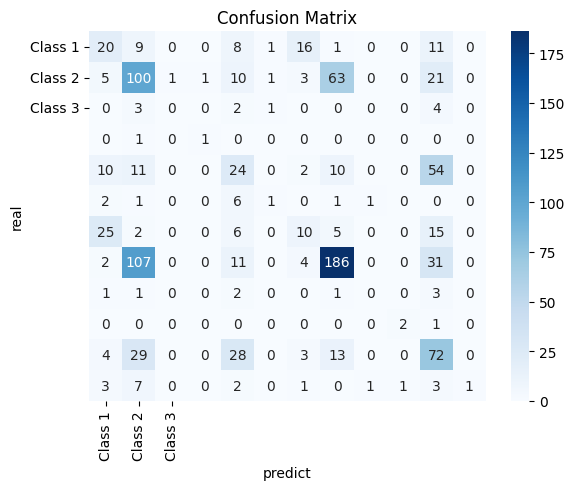

In [50]:
import matplotlib.pyplot as plt 
import seaborn as sns 
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)

plt.Figure(figsize=(10,7))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Class 1', 'Class 2', 'Class 3'], yticklabels=['Class 1', 'Class 2', 'Class 3'])
plt.title('Confusion Matrix')
plt.xlabel('predict')
plt.ylabel('real')
plt.show()

4.3 Baseline Model

In [51]:
from sklearn.dummy import DummyClassifier

In [52]:
baseline_model = DummyClassifier(strategy='most_frequent')
baseline_model.fit(X_train_scaled, y_train)

y_pred_baseline = baseline_model.predict(X_test_scaled)

In [53]:
baseline_accuracy = accuracy_score(y_test, y_pred_baseline)
baseline_precision = precision_score(y_test, y_pred_baseline, average='weighted')
baseline_recall = recall_score(y_test, y_pred_baseline, average='weighted')
baseline_f1 = f1_score(y_test, y_pred_baseline, average='weighted')

C:\Users\User\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [54]:
print("\nBaseline Model Evaluation:")
print(f"Accuracy: {baseline_accuracy:.4f}")
print(f"Precision: {baseline_precision:.4f}")
print(f"Recall: {baseline_recall:.4f}")
print(f"F1-score: {baseline_f1:.4f}")


Baseline Model Evaluation:
Accuracy: 0.3448
Precision: 0.1189
Recall: 0.3448
F1-score: 0.1768


4.4 مقایسه مدل svm با مدل baseline

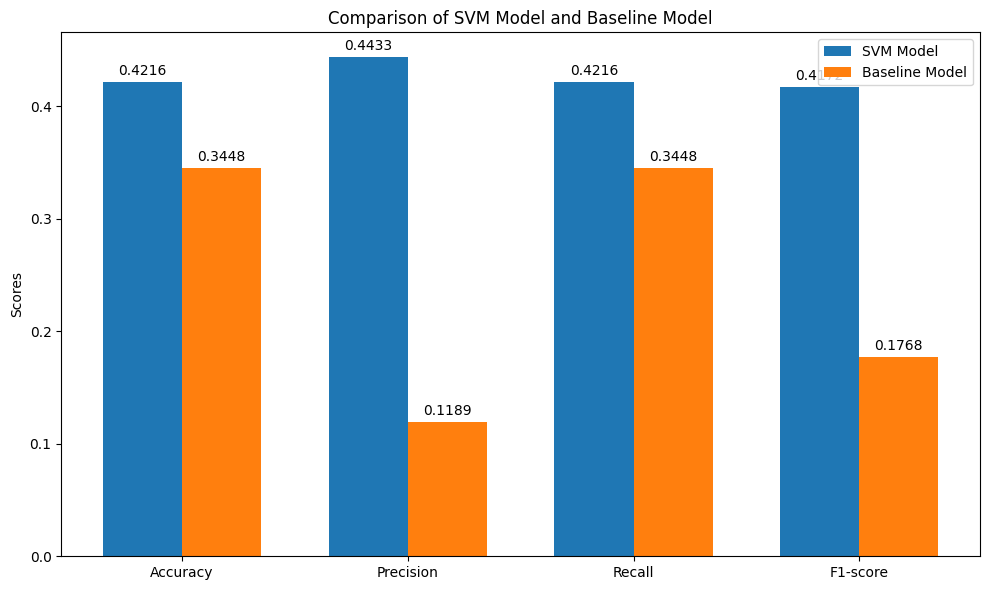

In [55]:
import matplotlib.pyplot as plt
import numpy as np

metrics = ['Accuracy', 'Precision', 'Recall', 'F1-score']
svm_scores = [accuracy, precision, recall, f1]
baseline_scores = [baseline_accuracy, baseline_precision, baseline_recall, baseline_f1]

x = np.arange(len(metrics)) 
width = 0.35  

fig, ax = plt.subplots(figsize=(10, 6))

rects1 = ax.bar(x - width/2, svm_scores, width, label='SVM Model')
rects2 = ax.bar(x + width/2, baseline_scores, width, label='Baseline Model')

ax.set_ylabel('Scores')
ax.set_title('Comparison of SVM Model and Baseline Model')
ax.set_xticks(x)
ax.set_xticklabels(metrics)
ax.legend()

def add_values(rects):
    for rect in rects:
        height = rect.get_height()
        ax.annotate(f'{height:.4f}',
                    xy=(rect.get_x() + rect.get_width() / 2, height),
                    xytext=(0, 3), 
                    textcoords="offset points",
                    ha='center', va='bottom')

add_values(rects1)
add_values(rects2)

plt.tight_layout()
plt.show()
